In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('placement.csv')

In [3]:
df

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0
...,...,...,...,...
95,95,4.3,200.0,0
96,96,4.4,42.0,0
97,97,6.7,182.0,1
98,98,6.3,103.0,1


In [4]:
df.shape

(100, 4)

# Steps

 0. Preprocess + EDA + Feature Selection
 1. Extract input and output cols
 2. Scale the values
 3. Train test split
 4. Train the model
 5. Evaluate the model/model selection
 6. Deploy the model

In [5]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [7]:
# remove unnamed col

df.drop(columns=['Unnamed: 0'], inplace=True)

In [8]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [9]:
import matplotlib.pyplot as plt

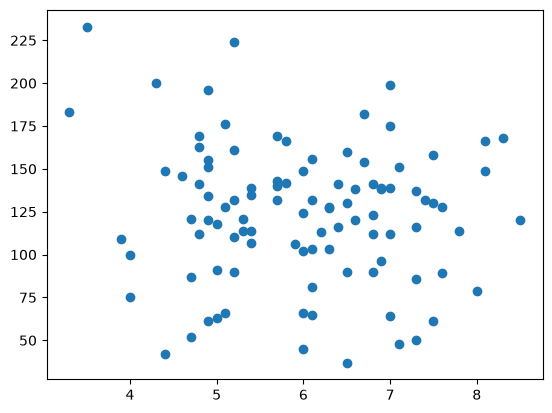

In [10]:
plt.scatter(df['cgpa'],df['iq'])
plt.show()

In [11]:
# Extract input and output cols

X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [12]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [13]:
y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [14]:
# %pip install -U scikit-learn


In [17]:
# Train test split
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.1) # here 0.1 is 10% data is use for testing

In [18]:
X_train

,cgpa,iq
66,6.9,96.0
69,8.5,120.0
48,6.6,138.0
8,6.1,156.0
4,5.8,142.0
...,...,...
15,5.1,176.0
83,7.5,130.0
47,5.2,161.0
16,5.2,224.0


In [19]:
X_test

,cgpa,iq
41,5.4,114.0
55,7.8,114.0
20,6.6,120.0
73,4.9,61.0
9,5.1,66.0
53,8.3,168.0
42,7.6,89.0
49,5.4,135.0
45,6.0,66.0
50,3.5,233.0


In [20]:
y_train

66    1
69    1
48    1
8     0
4     0
     ..
15    0
83    1
47    0
16    0
18    0
Name: placement, Length: 90, dtype: int64

In [21]:
y_test

41    0
55    1
20    1
73    0
9     0
53    1
42    1
49    0
45    1
50    0
Name: placement, dtype: int64

In [22]:
# Scalar

from sklearn.preprocessing import StandardScaler

In [23]:
scalar = StandardScaler()

In [25]:
X_train = scalar.fit_transform(X_train)
X_train

array([[ 0.83285548, -0.74072286],
       [ 2.28656686, -0.11377875],
       [ 0.56028459,  0.35642934],
       [ 0.10599979,  0.82663743],
       [-0.1665711 ,  0.46092003],
       [-0.98428375,  1.87154429],
       [ 0.83285548,  0.35642934],
       [-0.52999894, -0.45337348],
       [ 0.37857067, -0.21826943],
       [-0.89342678, -0.87133622],
       [-0.71171286,  0.19969331],
       [-0.71171286, -0.37500546],
       [-0.98428375,  0.80051476],
       [ 0.01514283, -0.00928806],
       [ 0.92371244,  1.32296819],
       [ 1.19628332, -1.94236575],
       [-1.43856855,  0.64377873],
       [-1.8019964 , -1.28929896],
       [-1.89285336, -0.40112813],
       [ 0.28771371, -0.55786416],
       [ 0.74199852,  0.43479735],
       [-0.6208559 , -0.27051478],
       [-1.16599767, -1.89012041],
       [ 1.46885421,  0.09520263],
       [ 0.65114155,  1.50582689],
       [-0.6208559 , -0.08765608],
       [ 0.46942763, -0.89745889],
       [ 0.74199852, -0.03541073],
       [-1.16599767,

In [26]:
X_test = scalar.transform(X_test)
X_test

C:\Users\himan\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


array([[  5.4, 114. ],
       [  7.8, 114. ],
       [  6.6, 120. ],
       [  4.9,  61. ],
       [  5.1,  66. ],
       [  8.3, 168. ],
       [  7.6,  89. ],
       [  5.4, 135. ],
       [  6. ,  66. ],
       [  3.5, 233. ]])

In [27]:
# Train the model
from sklearn.linear_model import LogisticRegression

In [28]:
clf = LogisticRegression()

In [29]:
clf.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [32]:
y_pred = clf.predict(X_test)

In [31]:
y_test

41    0
55    1
20    1
73    0
9     0
53    1
42    1
49    0
45    1
50    0
Name: placement, dtype: int64

In [33]:
from sklearn.metrics import accuracy_score

In [34]:
accuracy_score(y_test,y_pred)

0.5

In [ ]:
%pip install mlxtend

In [37]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

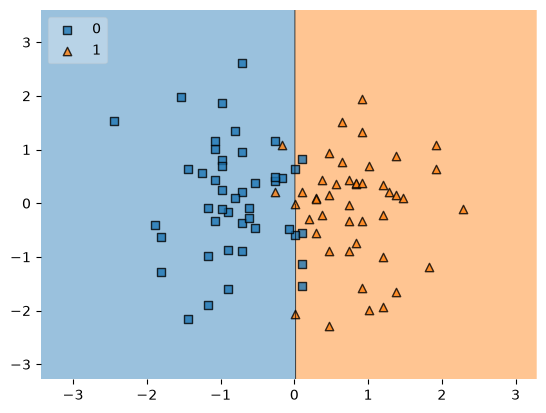

In [38]:
# Plotting decision regions
plot_decision_regions(X_train, y_train.values, clf=clf, legend=2)

In [2]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)

color = [["Red"],
         ["Blue"],
         ["Green"]]

encoded = encoder.fit_transform(color)

print(encoded)

[[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]


In [3]:
import pandas as pd

df = pd.DataFrame({
    "Gender": ["Male", "Female", "Male", "Female"]
})

In [4]:
pd.get_dummies(df["Gender"])

,Female,Male
0,False,True
1,True,False
2,False,True
3,True,False


In [5]:
pd.get_dummies(df["Gender"], drop_first=True)

,Male
0,True
1,False
2,True
3,False


In [6]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop="first", sparse_output=False)

encoded = encoder.fit_transform(df[["Gender"]])

print(encoded)

[[1.]
 [0.]
 [1.]
 [0.]]


In [1]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

df = pd.DataFrame({
    "Age":[25,30,35],
    "Salary":[50000,60000,70000],
    "Gender":["Male","Female","Male"],
    "Education":["College","Master","PhD"]
})

ct = ColumnTransformer(
    transformers=[
        ("num",
         StandardScaler(),
         ["Age","Salary"]),

        ("gender",
         OneHotEncoder(),
         ["Gender"]),

        ("edu",
         OrdinalEncoder(
             categories=[["College","Master","PhD"]]
         ),
         ["Education"])
    ]
)

result = ct.fit_transform(df)

print(result)

[[-1.22474487 -1.22474487  0.          1.          0.        ]
 [ 0.          0.          1.          0.          1.        ]
 [ 1.22474487  1.22474487  0.          1.          2.        ]]
